<center> <img src = https://raw.githubusercontent.com/AndreyRysistov/DatasetsForPandas/main/hh%20label.jpg alt="drawing" style="width:400px;">

# <center> Проект: Анализ резюме из HeadHunter
   

In [109]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns


# Исследование структуры данных

1. Прочитайте данные с помощью библиотеки Pandas. Совет: перед чтением обратите внимание на разделитель внутри файла. 

In [110]:
hh_data = pd.read_csv("data/dst-3.0_16_1_hh_database.csv", sep=";", dtype=object)

table_shape = hh_data.shape
display(f"Размер таблицы: {table_shape}")


'Размер таблицы: (44744, 12)'

2. Выведите несколько первых (последних) строк таблицы, чтобы убедиться в том, что ваши данные не повреждены. Ознакомьтесь с признаками и их структурой.

In [111]:
display(hh_data.head())


,"Пол, возраст",ЗП,Ищет работу на должность:,"Город, переезд, командировки",Занятость,График,Опыт работы,Последнее/нынешнее место работы,Последняя/нынешняя должность,Образование и ВУЗ,Обновление резюме,Авто
0,"Мужчина , 39 лет , родился 27 ноября 1979",29000 руб.,Системный администратор,"Советск (Калининградская область) , не готов к...","частичная занятость, проектная работа, полная ...","гибкий график, полный день, сменный график, ва...",Опыт работы 16 лет 10 месяцев Август 2010 — п...,"МАОУ ""СОШ № 1 г.Немана""",Системный администратор,Неоконченное высшее образование 2000 Балтийск...,16.04.2019 15:59,Имеется собственный автомобиль
1,"Мужчина , 60 лет , родился 20 марта 1959",40000 руб.,Технический писатель,"Королев , не готов к переезду , готов к редким...","частичная занятость, проектная работа, полная ...","гибкий график, полный день, сменный график, уд...",Опыт работы 19 лет 5 месяцев Январь 2000 — по...,Временный трудовой коллектив,"Менеджер проекта, Аналитик, Технический писатель",Высшее образование 1981 Военно-космическая ак...,12.04.2019 08:42,Не указано
2,"Женщина , 36 лет , родилась 12 августа 1982",20000 руб.,Оператор,"Тверь , не готова к переезду , не готова к ком...",полная занятость,полный день,Опыт работы 10 лет 3 месяца Октябрь 2004 — Де...,ПАО Сбербанк,Кассир-операционист,Среднее специальное образование 2002 Профессио...,16.04.2019 08:35,Не указано
3,"Мужчина , 38 лет , родился 25 июня 1980",100000 руб.,Веб-разработчик (HTML / CSS / JS / PHP / базы ...,"Саратов , не готов к переезду , готов к редким...","частичная занятость, проектная работа, полная ...","гибкий график, удаленная работа",Опыт работы 18 лет 9 месяцев Август 2017 — Ап...,OpenSoft,Инженер-программист,Высшее образование 2002 Саратовский государст...,08.04.2019 14:23,Не указано
4,"Женщина , 26 лет , родилась 3 марта 1993",140000 руб.,Региональный менеджер по продажам,"Москва , не готова к переезду , готова к коман...",полная занятость,полный день,Опыт работы 5 лет 7 месяцев Региональный мене...,Мармелад,Менеджер по продажам,Высшее образование 2015 Кгу Психологии и педаг...,22.04.2019 10:32,Не указано


3. Выведите основную информацию о числе непустых значений в столбцах и их типах в таблице.

In [112]:
hh_data.info()

for column, dtype in hh_data.dtypes.items():
    display(f"Тип столбца {column}: {dtype}")


<class 'pandas.DataFrame'>
RangeIndex: 44744 entries, 0 to 44743
Data columns (total 12 columns):
 #   Column                           Non-Null Count  Dtype 
---  ------                           --------------  ----- 
 0   Пол, возраст                     44744 non-null  object
 1   ЗП                               44744 non-null  object
 2   Ищет работу на должность:        44744 non-null  object
 3   Город, переезд, командировки     44744 non-null  object
 4   Занятость                        44744 non-null  object
 5   График                           44744 non-null  object
 6   Опыт работы                      44576 non-null  object
 7   Последнее/нынешнее место работы  44743 non-null  object
 8   Последняя/нынешняя должность     44742 non-null  object
 9   Образование и ВУЗ                44744 non-null  object
 10  Обновление резюме                44744 non-null  object
 11  Авто                             44744 non-null  object
dtypes: object(12)
memory usage: 4.1+ MB


'Тип столбца Пол, возраст: object'

'Тип столбца ЗП: object'

'Тип столбца Ищет работу на должность:: object'

'Тип столбца Город, переезд, командировки: object'

'Тип столбца Занятость: object'

... (3 outputs left out)

'Тип столбца Последняя/нынешняя должность: object'

'Тип столбца Образование и ВУЗ: object'

'Тип столбца Обновление резюме: object'

'Тип столбца Авто: object'

4. Обратите внимание на информацию о числе непустых значений.

In [113]:
display(f"Количество резюме: {len(hh_data)}")

missing_counts = hh_data.isna().sum()
display("Количество пропусков в каждом столбце:")
display(missing_counts)

columns_with_missing = missing_counts[missing_counts > 0]
display("Признаки с пропусками:")
for column, count in columns_with_missing.items():
    display(f"{column}: {count}")

'Количество резюме: 44744'

'Количество пропусков в каждом столбце:'

Пол, возраст                         0
ЗП                                   0
Ищет работу на должность:            0
Город, переезд, командировки         0
Занятость                            0
График                               0
Опыт работы                        168
Последнее/нынешнее место работы      1
Последняя/нынешняя должность         2
Образование и ВУЗ                    0
Обновление резюме                    0
Авто                                 0
dtype: int64

'Признаки с пропусками:'

'Опыт работы: 168'

'Последнее/нынешнее место работы: 1'

'Последняя/нынешняя должность: 2'

5. Выведите основную статистическую информацию о столбцах.


In [114]:
display(hh_data.describe(include="all"))

unique_experience_count = hh_data["Опыт работы"].nunique()
display(f"Уникальных значений опыта: {unique_experience_count}")
popular_position = hh_data["Ищет работу на должность:"].mode()[0]
display(f"Самая частая должность: {popular_position}")
popular_position_count = hh_data["Ищет работу на должность:"].value_counts().iloc[0]
display(f"Количество таких резюме: {popular_position_count}")


,"Пол, возраст",ЗП,Ищет работу на должность:,"Город, переезд, командировки",Занятость,График,Опыт работы,Последнее/нынешнее место работы,Последняя/нынешняя должность,Образование и ВУЗ,Обновление резюме,Авто
count,44744,44744,44744,44744,44744,44744,44576,44743,44742,44744,44744,44744
unique,16003,690,14929,10063,38,47,44413,30214,16927,40148,18838,2
top,"Мужчина , 32 года , родился 17 сентября 1986",50000 руб.,Системный администратор,"Москва , не готов к переезду , не готов к кома...",полная занятость,полный день,Опыт работы 10 лет 8 месяцев Апрель 2018 — по...,Индивидуальное предпринимательство / частная п...,Системный администратор,Высшее образование 2014 Московский технически...,07.05.2019 09:50,Не указано
freq,18,4064,3099,1261,30026,22727,3,935,2062,4,25,32268


'Уникальных значений опыта: 44413'

'Самая частая должность: Системный администратор'

'Количество таких резюме: 3099'

В столбце "Опыт работы" - **44 413 уникальных значений**. Самая распространённая искомая должность - **Системный администратор** (3 099 резюме).

# Преобразование данных

1. Начнем с простого - с признака **"Образование и ВУЗ"**. Его текущий формат это: **<Уровень образования год выпуска ВУЗ специальность...>**. Например:
* Высшее образование 2016 Московский авиационный институт (национальный исследовательский университет)...
* Неоконченное высшее образование 2000  Балтийская государственная академия рыбопромыслового флота…
Нас будет интересовать только уровень образования.

Создайте с помощью функции-преобразования новый признак **"Образование"**, который должен иметь 4 категории: "высшее", "неоконченное высшее", "среднее специальное" и "среднее".

Выполните преобразование, ответьте на контрольные вопросы и удалите признак "Образование и ВУЗ".

Совет: обратите внимание на структуру текста в столбце **"Образование и ВУЗ"**. Гарантируется, что текущий уровень образования соискателя всегда находится в первых 2ух слов и начинается с заглавной буквы. Воспользуйтесь этим.

*Совет: проверяйте полученные категории, например, с помощью метода unique()*


In [115]:
def get_education(value):
    if value.startswith("Неоконченное высшее"):
        return "неоконченное высшее"
    if value.startswith("Высшее"):
        return "высшее"
    if value.startswith("Среднее специальное"):
        return "среднее специальное"
    return "среднее"

hh_data["Образование"] = hh_data["Образование и ВУЗ"].apply(get_education)

display(hh_data["Образование"].unique())
display(hh_data["Образование"].value_counts())

hh_data = hh_data.drop(columns=["Образование и ВУЗ"])


<StringArray>
['неоконченное высшее', 'высшее', 'среднее специальное', 'среднее']
Length: 4, dtype: str

Образование
высшее                 33863
среднее специальное     5765
неоконченное высшее     4557
среднее                  559
Name: count, dtype: int64

2. Теперь нас интересует столбец **"Пол, возраст"**. Сейчас он представлен в формате **<Пол , возраст , дата рождения >**. Например:
* Мужчина , 39 лет , родился 27 ноября 1979 
* Женщина , 21 год , родилась 13 января 2000
Как вы понимаете, нам необходимо выделить каждый параметр в отдельный столбец.

Создайте два новых признака **"Пол"** и **"Возраст"**. При этом важно учесть:
* Признак пола должен иметь 2 уникальных строковых значения: 'М' - мужчина, 'Ж' - женщина. 
* Признак возраста должен быть представлен целыми числами.

Выполните преобразование, ответьте на контрольные вопросы и удалите признак **"Пол, возраст"** из таблицы.

*Совет: обратите внимание на структуру текста в столбце, в части на то, как разделены параметры пола, возраста и даты рождения между собой - символом ' , '. 
Гарантируется, что структура одинакова для всех строк в таблице. Вы можете воспользоваться этим.*


In [116]:
PERCENT_FACTOR = 100

def get_gender(value):
    return value[0]


def get_age(value):
    return int(value.split(",")[1].split()[0])


hh_data["Пол"] = hh_data["Пол, возраст"].apply(get_gender)
hh_data["Возраст"] = hh_data["Пол, возраст"].apply(get_age)

female_percent = (hh_data["Пол"] == "Ж").mean() * PERCENT_FACTOR
average_age = hh_data["Возраст"].mean()

display(f"Доля женских резюме: {female_percent:.2f}%")
display(f"Средний возраст соискателей: {average_age:.1f} года")

hh_data = hh_data.drop(columns=["Пол, возраст"])


'Доля женских резюме: 19.07%'

'Средний возраст соискателей: 32.2 года'

3. Следующим этапом преобразуем признак **"Опыт работы"**. Его текущий формат - это: **<Опыт работы: n лет m месяцев, периоды работы в различных компаниях…>**. 

Из столбца нам необходимо выделить общий опыт работы соискателя в месяцах, новый признак назовем "Опыт работы (месяц)"

Для начала обсудим условия решения задачи:
* Во-первых, в данном признаке есть пропуски. Условимся, что если мы встречаем пропуск, оставляем его как есть (функция-преобразование возвращает NaN)
* Во-вторых, в данном признаке есть скрытые пропуски. Для некоторых соискателей в столбце стоит значения "Не указано". Их тоже обозначим как NaN (функция-преобразование возвращает NaN)
* В-третьих, нас не интересует информация, которая описывается после указания опыта работы (периоды работы в различных компаниях)
* В-четвертых, у нас есть проблема: опыт работы может быть представлен только в годах или только месяцах. Например, можно встретить следующие варианты:
    * Опыт работы 3 года 2 месяца…
    * Опыт работы 4 года…
    * Опыт работы 11 месяцев…
    * Учитывайте эту особенность в вашем коде

Учитывайте эту особенность в вашем коде

В результате преобразования у вас должен получиться столбец, содержащий информацию о том, сколько месяцев проработал соискатель.
Выполните преобразование, ответьте на контрольные вопросы и удалите столбец **"Опыт работы"** из таблицы.


In [117]:
MONTHS_PER_YEAR = 12
EXPERIENCE_PREFIX_WORDS = 7
NEXT_WORD_OFFSET = 1


def get_experience(value):
    if pd.isna(value) or value.startswith("Не указано"):
        return np.nan

    words = value.split()[:EXPERIENCE_PREFIX_WORDS]
    months = 0

    for number, unit in zip(words, words[NEXT_WORD_OFFSET:]):
        if number.isdigit():
            if unit in ["год", "года", "лет"]:
                months += int(number) * MONTHS_PER_YEAR
            elif unit in ["месяц", "месяца", "месяцев"]:
                months += int(number)

    return months

hh_data["Опыт работы (месяц)"] = hh_data["Опыт работы"].apply(get_experience)

display(hh_data["Опыт работы (месяц)"].describe())
median_experience = hh_data["Опыт работы (месяц)"].median()
display(f"Медианный опыт работы: {median_experience:g} месяцев")

hh_data = hh_data.drop(columns=["Опыт работы"])


count    44574.000000
mean       114.418944
std         79.047861
min          1.000000
25%         57.000000
50%        100.000000
75%        154.000000
max       1188.000000
Name: Опыт работы (месяц), dtype: float64

'Медианный опыт работы: 100 месяцев'

Медианный опыт работы - **100 месяцев**.

4. Хорошо идем! Следующий на очереди признак "Город, переезд, командировки". Информация в нем представлена в следующем виде: **<Город , (метро) , готовность к переезду (города для переезда) , готовность к командировкам>**. В скобках указаны необязательные параметры строки. Например, можно встретить следующие варианты:

* Москва , не готов к переезду , готов к командировкам
* Москва , м. Беломорская , не готов к переезду, не готов к командировкам
* Воронеж , готов к переезду (Сочи, Москва, Санкт-Петербург) , готов к командировкам

Создадим отдельные признаки **"Город"**, **"Готовность к переезду"**, **"Готовность к командировкам"**. При этом важно учесть:

* Признак **"Город"** должен содержать только 4 категории: "Москва", "Санкт-Петербург" и "город-миллионник" (их список ниже), остальные обозначьте как "другие".

    Список городов-миллионников:
    
   <code>million_cities = ['Новосибирск', 'Екатеринбург','Нижний Новгород','Казань', 'Челябинск','Омск', 'Самара', 'Ростов-на-Дону', 'Уфа', 'Красноярск', 'Пермь', 'Воронеж','Волгоград']
    </code>
    Инфорация о метро, рядом с которым проживает соискатель нас не интересует.
* Признак **"Готовность к переезду"** должен иметь два возможных варианта: True или False. Обратите внимание, что возможны несколько вариантов описания готовности к переезду в признаке "Город, переезд, командировки". Например:
    * … , готов к переезду , …
    * … , не готова к переезду , …
    * … , готова к переезду (Москва, Санкт-Петербург, Ростов-на-Дону)
    * … , хочу переехать (США) , …
    
    Нас интересует только сам факт возможности или желания переезда.
* Признак **"Готовность к командировкам"** должен иметь два возможных варианта: True или False. Обратите внимание, что возможны несколько вариантов описания готовности к командировкам в признаке "Город, переезд, командировки". Например:
    * … , готов к командировкам , … 
    * … , готова к редким командировкам , …
    * … , не готов к командировкам , …
    
    Нас интересует только сам факт готовности к командировке.
    
    Еще один важный факт: при выгрузки данных у некоторых соискателей "потерялась" информация о готовности к командировкам. Давайте по умолчанию будем считать, что такие соискатели не готовы к командировкам.
    
Выполните преобразования и удалите столбец **"Город, переезд, командировки"** из таблицы.

*Совет: обратите внимание на то, что структура текста может меняться в зависимости от указания ближайшего метро. Учите это, если будете использовать порядок слов в своей программе.*


In [118]:
PERCENT_FACTOR = 100

million_cities = ["Новосибирск", "Екатеринбург", "Нижний Новгород", "Казань", "Челябинск", "Омск", "Самара", "Ростов-на-Дону", "Уфа", "Красноярск", "Пермь", "Воронеж", "Волгоград"]


def get_city(value):
    city = value.split(",")[0].strip()
    if city in ["Москва", "Санкт-Петербург"]:
        return city
    if city in million_cities:
        return "город-миллионник"
    return "другие"


def can_move(value):
    if "не готов к переезду" in value or "не готова к переезду" in value:
        return False
    return "готов к переезду" in value or "готова к переезду" in value or "хочу переехать" in value


def can_travel(value):
    if "не готов к командировкам" in value or "не готова к командировкам" in value:
        return False

    if "готов к командировкам" in value or "готова к командировкам" in value:
        return True

    if "готов к редким командировкам" in value or "готова к редким командировкам" in value:
        return True

    # Если информация о командировках отсутствует, считаем, что соискатель не готов.
    return False


hh_data["Город"] = hh_data["Город, переезд, командировки"].apply(get_city)
hh_data["Готовность к переезду"] = hh_data["Город, переезд, командировки"].apply(can_move)
hh_data["Готовность к командировкам"] = hh_data["Город, переезд, командировки"].apply(can_travel)

display(hh_data["Город"].value_counts())
relocation_counts = hh_data["Готовность к переезду"].value_counts().to_dict()
display(f"Готовность к переезду: {relocation_counts}")
travel_counts = hh_data["Готовность к командировкам"].value_counts().to_dict()
display(f"Готовность к командировкам: {travel_counts}")

spb_percent = (hh_data["Город"] == "Санкт-Петербург").mean() * PERCENT_FACTOR
move_travel_percent = (hh_data["Готовность к переезду"] & hh_data["Готовность к командировкам"]).mean() * PERCENT_FACTOR

display(f"Соискателей из Санкт-Петербурга: {spb_percent:.0f}%")
display(f"Готовы к переезду и командировкам: {move_travel_percent:.0f}%")

hh_data = hh_data.drop(columns=["Город, переезд, командировки"])


Город
Москва              16621
другие              15854
город-миллионник     7332
Санкт-Петербург      4937
Name: count, dtype: int64

'Готовность к переезду: {False: 28719, True: 16025}'

'Готовность к командировкам: {True: 31640, False: 13104}'

'Соискателей из Санкт-Петербурга: 11%'

'Готовы к переезду и командировкам: 32%'

Соискателей из Санкт-Петербурга - **11%**. Готовы одновременно к переезду и командировкам - **32%**.

5. Рассмотрим поближе признаки **"Занятость"** и **"График"**. Сейчас признаки представляют собой набор категорий желаемой занятости (полная занятость, частичная занятость, проектная работа, волонтерство, стажировка) и желаемого графика работы (полный день, сменный график, гибкий график, удаленная работа, вахтовый метод).
На сайте hh.ru соискатель может указывать различные комбинации данных категорий, например:
* полная занятость, частичная занятость
* частичная занятость, проектная работа, волонтерство
* полный день, удаленная работа
* вахтовый метод, гибкий график, удаленная работа, полная занятость

Такой вариант признаков имеет множество различных комбинаций, а значит множество уникальных значений, что мешает анализу. Нужно это исправить!

Давайте создадим признаки-мигалки для каждой категории: если категория присутствует в списке желаемых соискателем, то в столбце на месте строки рассматриваемого соискателя ставится True, иначе - False.

Такой метод преобразования категориальных признаков называется One Hot Encoding и его схема представлена на рисунке ниже:
<img src=https://raw.githubusercontent.com/AndreyRysistov/DatasetsForPandas/main/ohe.jpg>
Выполните данное преобразование для признаков "Занятость" и "График", ответьте на контрольные вопросы, после чего удалите их из таблицы

In [119]:
employment_types = ["полная занятость", "частичная занятость", "проектная работа", "волонтерство", "стажировка"]
schedule_types = ["полный день", "сменный график", "гибкий график", "удаленная работа", "вахтовый метод"]

for category in employment_types:
    hh_data[category] = hh_data["Занятость"].apply(lambda value: category in value.split(", "))

for category in schedule_types:
    hh_data[category] = hh_data["График"].apply(lambda value: category in value.split(", "))

display(hh_data[employment_types + schedule_types].sum())

project_volunteer = (hh_data["проектная работа"] & hh_data["волонтерство"]).sum()
shift_flexible = (hh_data["вахтовый метод"] & hh_data["гибкий график"]).sum()

project_volunteer_count = project_volunteer
display(f"Проектная работа и волонтёрство: {project_volunteer_count}")
shift_flexible_count = shift_flexible
display(f"Вахтовый метод и гибкий график: {shift_flexible_count}")

hh_data = hh_data.drop(columns=["Занятость", "График"])


полная занятость       43284
частичная занятость    13136
проектная работа        8068
волонтерство             486
стажировка              2804
полный день            41716
сменный график         12725
гибкий график          15584
удаленная работа       15022
вахтовый метод          3084
dtype: int64

'Проектная работа и волонтёрство: 436'

'Вахтовый метод и гибкий график: 2311'

Проектную работу и волонтёрство одновременно ищут **436 человек**. Вахтовый метод и гибкий график одновременно рассматривают **2 311 человек**.

6. (2 балла) Наконец, мы добрались до самого главного и самого важного - признака заработной платы **"ЗП"**. 
В чем наша беда? В том, что помимо желаемой заработной платы соискатель указывает валюту, в которой он бы хотел ее получать, например:
* 30000 руб.
* 50000 грн.
* 550 USD

Нам бы хотелось видеть заработную плату в единой валюте, например, в рублях. Возникает вопрос, а где взять курс валют по отношению к рублю?

На самом деле язык Python имеет в арсенале огромное количество возможностей получения данной информации, от обращения к API Центробанка, до использования специальных библиотек, например pycbrf. Однако, это не тема нашего проекта.

Поэтому мы пойдем в лоб: обратимся к специальным интернет-ресурсам для получения данных о курсе в виде текстовых файлов. Например, MDF.RU, данный ресурс позволяет удобно экспортировать данные о курсах различных валют и акций за указанные периоды в виде csv файлов. Мы уже сделали выгрузку курсов валют, которые встречаются в наших данных за период с 29.12.2017 по 05.12.2019. Скачать ее вы можете **на платформе**

Создайте новый DataFrame из полученного файла. В полученной таблице нас будут интересовать столбцы:
* "currency" - наименование валюты в ISO кодировке,
* "date" - дата, 
* "proportion" - пропорция, 
* "close" - цена закрытия (последний зафиксированный курс валюты на указанный день).


Перед вами таблица соответствия наименований иностранных валют в наших данных и их общепринятых сокращений, которые представлены в нашем файле с курсами валют. Пропорция - это число, за сколько единиц валюты указан курс в таблице с курсами. Например, для казахстанского тенге курс на 20.08.2019 составляет 17.197 руб. за 100 тенге, тогда итоговый курс равен - 17.197 / 100 = 0.17197 руб за 1 тенге.
Воспользуйтесь этой информацией в ваших преобразованиях.

<img src=https://raw.githubusercontent.com/AndreyRysistov/DatasetsForPandas/main/table.jpg>


Осталось только понять, откуда брать дату, по которой определяется курс? А вот же она - в признаке **"Обновление резюме"**, в нем содержится дата и время, когда соискатель выложил текущий вариант своего резюме. Нас интересует только дата, по ней бы и будем сопоставлять курсы валют.

Теперь у нас есть вся необходимая информация для того, чтобы создать признак "ЗП (руб)" - заработная плата в рублях.

После ответа на контрольные вопросы удалите исходный столбец заработной платы "ЗП" и все промежуточные столбцы, если вы их создавали.

Итак, давайте обсудим возможный алгоритм преобразования: 
1. Перевести признак "Обновление резюме" из таблицы с резюме в формат datetime и достать из него дату. В тот же формат привести признак "date" из таблицы с валютами.
2. Выделить из столбца "ЗП" сумму желаемой заработной платы и наименование валюты, в которой она исчисляется. Наименование валюты перевести в стандарт ISO согласно с таблицей выше.
3. Присоединить к таблице с резюме таблицу с курсами по столбцам с датой и названием валюты (подумайте, какой тип объединения надо выбрать, чтобы в таблице с резюме сохранились данные о заработной плате, изначально представленной в рублях). Значение close для рубля заполнить единицей 1 (курс рубля самого к себе)
4. Умножить сумму желаемой заработной платы на присоединенный курс валюты (close) и разделить на пропорцию (обратите внимание на пропуски после объединения в этих столбцах), результат занести в новый столбец "ЗП (руб)".


In [120]:
RUB_RATE = 1
RUB_PROPORTION = 1
RUBLES_PER_THOUSAND = 1_000

exchange_rates = pd.read_csv("data/ExchangeRates.csv")
exchange_rates["date"] = pd.to_datetime(exchange_rates["date"], format="%d/%m/%y")
hh_data["Обновление резюме"] = pd.to_datetime(hh_data["Обновление резюме"], format="%d.%m.%Y %H:%M").dt.normalize()

currency_names = {"руб.": "RUB", "бел.руб.": "BYN", "грн.": "UAH", "сум": "UZS",
                  "USD": "USD", "EUR": "EUR", "KZT": "KZT", "KGS": "KGS", "AZN": "AZN"}
salary_parts = hh_data["ЗП"].str.split()
hh_data["Сумма"] = salary_parts.str[0].astype(float)
hh_data["Валюта"] = salary_parts.str[-1].map(currency_names)

hh_data = hh_data.merge(
    exchange_rates[["currency", "date", "close", "proportion"]],
    left_on=["Валюта", "Обновление резюме"],
    right_on=["currency", "date"],
    how="left",
    validate="many_to_one"
)

rubles = hh_data["Валюта"] == "RUB"
hh_data.loc[rubles, "close"] = RUB_RATE
hh_data.loc[rubles, "proportion"] = RUB_PROPORTION

hh_data["ЗП (руб)"] = hh_data["Сумма"] * hh_data["close"] / hh_data["proportion"]

resume_count = len(hh_data)
display(f"Количество резюме: {resume_count}")
missing_rates_count = hh_data["ЗП (руб)"].isna().sum()
display(f"Зарплат без курса: {missing_rates_count}")
median_salary = hh_data["ЗП (руб)"].median()
display(f"Медианная зарплата, руб.: {median_salary}")
median_salary_thousands = round(hh_data["ЗП (руб)"].median() / RUBLES_PER_THOUSAND)
display(f"Медианная зарплата, тыс. руб.: {median_salary_thousands}")

hh_data = hh_data.drop(columns=["ЗП", "Сумма", "Валюта", "currency", "date", "close", "proportion"])


'Количество резюме: 44744'

'Зарплат без курса: 0'

'Медианная зарплата, руб.: 59019.0'

'Медианная зарплата, тыс. руб.: 59'

Медианная желаемая зарплата - **59 тысяч рублей** (59 019 рублей до округления).

# Исследование зависимостей в данных

1. Постройте распределение признака **"Возраст"**. Опишите распределение, отвечая на следующие вопросы: чему равна мода распределения, каковы предельные значения признака, в каком примерном интервале находится возраст большинства соискателей? Есть ли аномалии для признака возраста, какие значения вы бы причислили к их числу?
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*

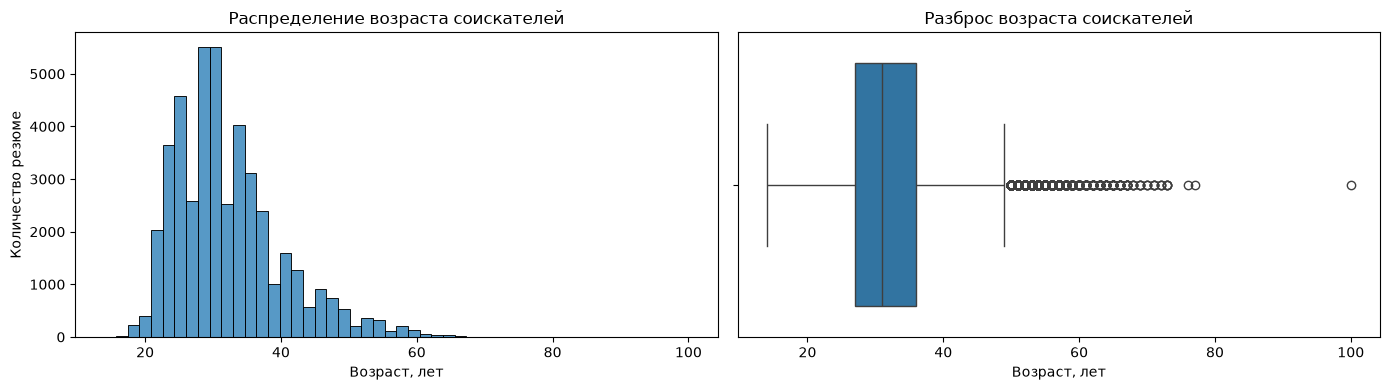

'Мода: [30]'

count    44744.000000
mean        32.196741
std          7.929800
min         14.000000
25%         27.000000
50%         31.000000
75%         36.000000
max        100.000000
Name: Возраст, dtype: float64

'Границы выбросов по IQR: от 13.5 до 49.5 лет'

In [121]:
PLOT_SIZE = (14, 4)
AGE_BINS = 50
FIRST_QUARTILE = 0.25
THIRD_QUARTILE = 0.75
IQR_MULTIPLIER = 1.5

fig, axes = plt.subplots(1, 2, figsize=PLOT_SIZE)

sns.histplot(hh_data["Возраст"], bins=AGE_BINS, ax=axes[0])
axes[0].set_title("Распределение возраста соискателей")
axes[0].set_xlabel("Возраст, лет")
axes[0].set_ylabel("Количество резюме")

sns.boxplot(x=hh_data["Возраст"], ax=axes[1])
axes[1].set_title("Разброс возраста соискателей")
axes[1].set_xlabel("Возраст, лет")
plt.tight_layout()
plt.show()

age_mode = hh_data["Возраст"].mode().tolist()
display(f"Мода: {age_mode}")
display(hh_data["Возраст"].describe())

first_quartile = hh_data["Возраст"].quantile(FIRST_QUARTILE)
third_quartile = hh_data["Возраст"].quantile(THIRD_QUARTILE)
iqr = third_quartile - first_quartile

lower_bound = first_quartile - IQR_MULTIPLIER * iqr
upper_bound = third_quartile + IQR_MULTIPLIER * iqr

display(f"Границы выбросов по IQR: от {lower_bound:.1f} до {upper_bound:.1f} лет")


Мода распределения - **30 лет**. Возраст в выборке находится в пределах **от 14 до 100 лет**. Половина соискателей - в диапазоне **27-36 лет**. Распределение скошено вправо: после основного пика число соискателей постепенно снижается.

На коробчатой диаграмме возраста от **50 лет** отмечаются как потенциальные выбросы по правилу 1,5 межквартильного размаха. По коробчатой диаграмме явно видно аномальное значение - **100 лет**. Это повод проверить записи, а не основание считать их ошибочными.

2. Постройте распределение признака **"Опыт работы (месяц)"**. Опишите данное распределение, отвечая на следующие вопросы: чему равна мода распределения, каковы предельные значения признака, в каком примерном интервале находится опыт работы большинства соискателей? Есть ли аномалии для признака опыта работы, какие значения вы бы причислили к их числу?
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*

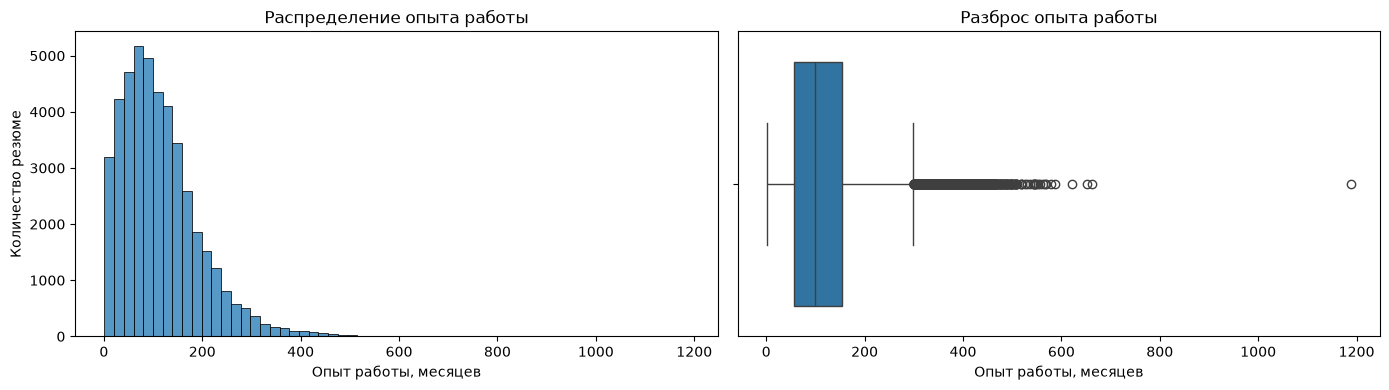

'Мода опыта работы (месяцы): 81'

count    44574.000000
mean       114.418944
std         79.047861
min          1.000000
25%         57.000000
50%        100.000000
75%        154.000000
max       1188.000000
Name: Опыт работы (месяц), dtype: float64

'Границы выбросов по IQR: от -88.5 до 299.5 месяцев'

In [122]:
PLOT_SIZE = (14, 4)
EXPERIENCE_BINS = 60
FIRST_QUARTILE = 0.25
THIRD_QUARTILE = 0.75
IQR_MULTIPLIER = 1.5

fig, axes = plt.subplots(1, 2, figsize=PLOT_SIZE)

sns.histplot(hh_data["Опыт работы (месяц)"], bins=EXPERIENCE_BINS, ax=axes[0])
axes[0].set_title("Распределение опыта работы")
axes[0].set_xlabel("Опыт работы, месяцев")
axes[0].set_ylabel("Количество резюме")

sns.boxplot(x=hh_data["Опыт работы (месяц)"], ax=axes[1])
axes[1].set_title("Разброс опыта работы")
axes[1].set_xlabel("Опыт работы, месяцев")
plt.tight_layout()
plt.show()

mode_experience = hh_data["Опыт работы (месяц)"].mode()
display(f"Мода опыта работы (месяцы): {mode_experience.iloc[0]:g}")
display(hh_data["Опыт работы (месяц)"].describe())

first_quartile = hh_data["Опыт работы (месяц)"].quantile(FIRST_QUARTILE)
third_quartile = hh_data["Опыт работы (месяц)"].quantile(THIRD_QUARTILE)
iqr = third_quartile - first_quartile

lower_bound = first_quartile - IQR_MULTIPLIER * iqr
upper_bound = third_quartile + IQR_MULTIPLIER * iqr

display(f"Границы выбросов по IQR: от {lower_bound:.1f} до {upper_bound:.1f} месяцев")


Мода опыта работы - **81 месяц**. Значения находятся в диапазоне **от 1 до 1 188 месяцев**. Половина непустых значений - от **57 до 154 месяцев**. Распределение скошено вправо: после основного пика встречаются всё более редкие большие значения.

По правилу 1,5 межквартильного размаха опыт от **300 месяцев** попадает в число потенциальных выбросов, но 25 лет стажа сами по себе не означают ошибку. Особенно стоит проверить максимум - **1 188 месяцев**, или 99 лет, а также случаи, когда опыт больше возраста соискателя.

3. Постройте распределение признака **"ЗП (руб)"**. Опишите данное распределение, отвечая на следующие вопросы: каковы предельные значения признака, в каком примерном интервале находится заработная плата большинства соискателей? Есть ли аномалии для признака возраста? Обратите внимание на гигантские размеры желаемой заработной платы.
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*


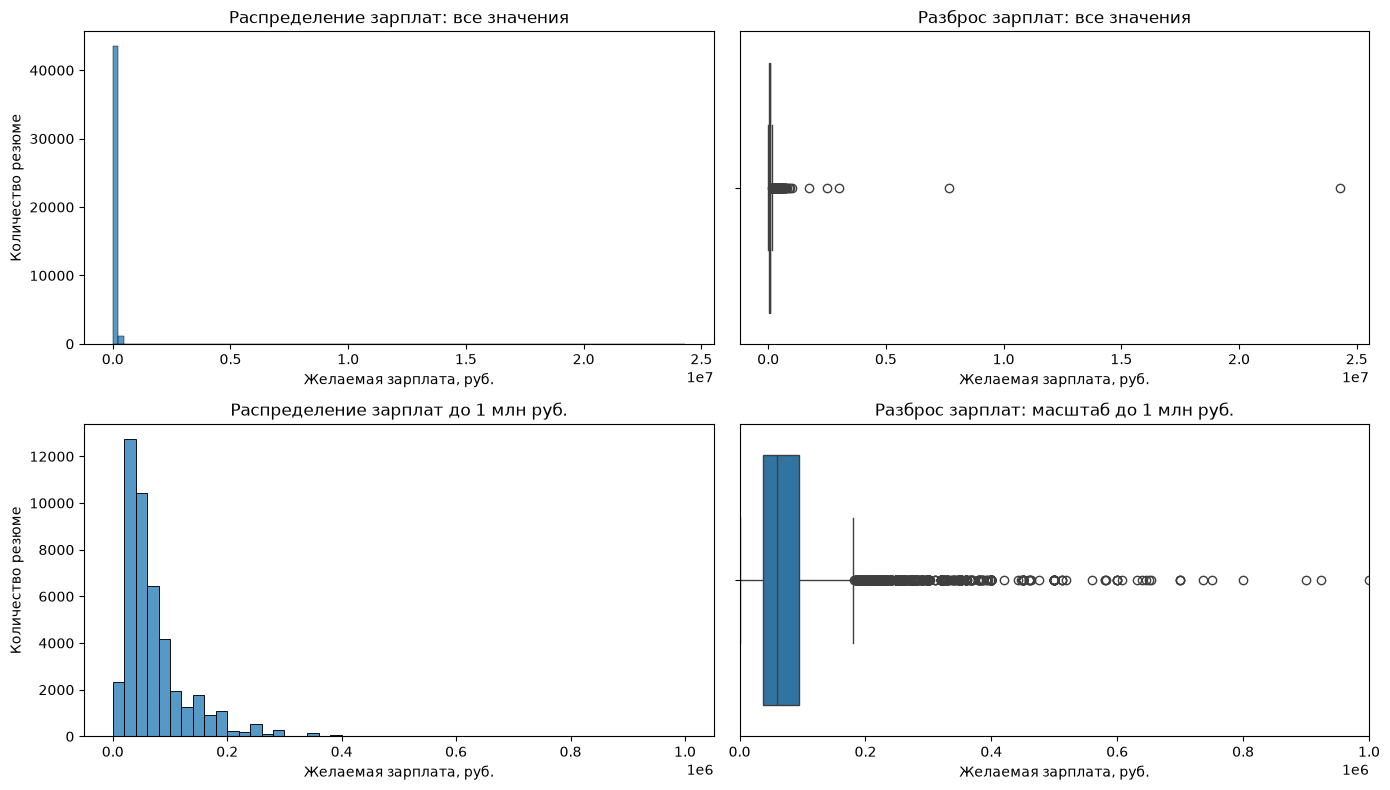

'Мода желаемой зарплаты: 50,000 рублей'

count    4.474400e+04
mean     7.653354e+04
std      1.359315e+05
min      1.000000e+00
25%      3.708220e+04
50%      5.901900e+04
75%      9.500000e+04
max      2.430488e+07
Name: ЗП (руб), dtype: float64

'Зарплата выше 1 млн рублей: 5 резюме'

'Границы выбросов по IQR: от -49,794.5 до 181,876.7 рублей'

In [123]:
FIRST_QUARTILE = 0.25
THIRD_QUARTILE = 0.75
IQR_MULTIPLIER = 1.5
PLOT_SIZE = (14, 8)
FULL_SALARY_BINS = 100
ZOOM_SALARY_BINS = 50
SALARY_LIMIT = 1_000_000

fig, axes = plt.subplots(2, 2, figsize=PLOT_SIZE)

sns.histplot(hh_data["ЗП (руб)"], bins=FULL_SALARY_BINS, ax=axes[0, 0])
axes[0, 0].set(title="Распределение зарплат: все значения", xlabel="Желаемая зарплата, руб.", ylabel="Количество резюме")
sns.boxplot(x=hh_data["ЗП (руб)"], ax=axes[0, 1])
axes[0, 1].set(title="Разброс зарплат: все значения", xlabel="Желаемая зарплата, руб.")

salary_below_million = hh_data[hh_data["ЗП (руб)"] <= SALARY_LIMIT]["ЗП (руб)"]
sns.histplot(salary_below_million, bins=ZOOM_SALARY_BINS, ax=axes[1, 0])
axes[1, 0].set(title="Распределение зарплат до 1 млн руб.", xlabel="Желаемая зарплата, руб.", ylabel="Количество резюме")
sns.boxplot(x=hh_data["ЗП (руб)"], ax=axes[1, 1])
axes[1, 1].set(title="Разброс зарплат: масштаб до 1 млн руб.", xlabel="Желаемая зарплата, руб.", xlim=(0, SALARY_LIMIT))
plt.tight_layout()
plt.show()

salary_mode = hh_data["ЗП (руб)"].mode()
display(f"Мода желаемой зарплаты: {salary_mode.iloc[0]:,.0f} рублей")
display(hh_data["ЗП (руб)"].describe())
above_salary_limit = (hh_data["ЗП (руб)"] > SALARY_LIMIT).sum()
display(f"Зарплата выше 1 млн рублей: {above_salary_limit} резюме")

first_quartile = hh_data["ЗП (руб)"].quantile(FIRST_QUARTILE)
third_quartile = hh_data["ЗП (руб)"].quantile(THIRD_QUARTILE)
iqr = third_quartile - first_quartile

lower_bound = first_quartile - IQR_MULTIPLIER * iqr
upper_bound = third_quartile + IQR_MULTIPLIER * iqr

display(f"Границы выбросов по IQR: от {lower_bound:,.1f} до {upper_bound:,.1f} рублей")


Мода желаемой зарплаты после пересчёта валют - **50 000 рублей**. Значения находятся в диапазоне **от 1 до 24 304 876 рублей**. Половина соискателей указала сумму примерно от **37 до 95 тысяч рублей**. Распределение скошено вправо.

На нижних графиках показан масштаб до 1 млн рублей, чтобы рассмотреть основную часть распределения. По правилу 1,5 межквартильного размаха значения выше примерно **181 877 рублей** являются потенциальными выбросами, но высокая зарплата сама по себе не означает ошибку. Особенно подозрительны значения в 1 рубль и более 24 млн рублей - их стоит проверить.

Заработную плату строго выше 1 млн рублей указали 5 соискателей.

4. Постройте диаграмму, которая показывает зависимость **медианной** желаемой заработной платы (**"ЗП (руб)"**) от уровня образования (**"Образование"**). Используйте для диаграммы данные о резюме, где желаемая заработная плата меньше 1 млн рублей.
*Сделайте выводы по представленной диаграмме: для каких уровней образования наблюдаются наибольшие и наименьшие уровни желаемой заработной платы? Как вы считаете, важен ли признак уровня образования при прогнозировании заработной платы?*

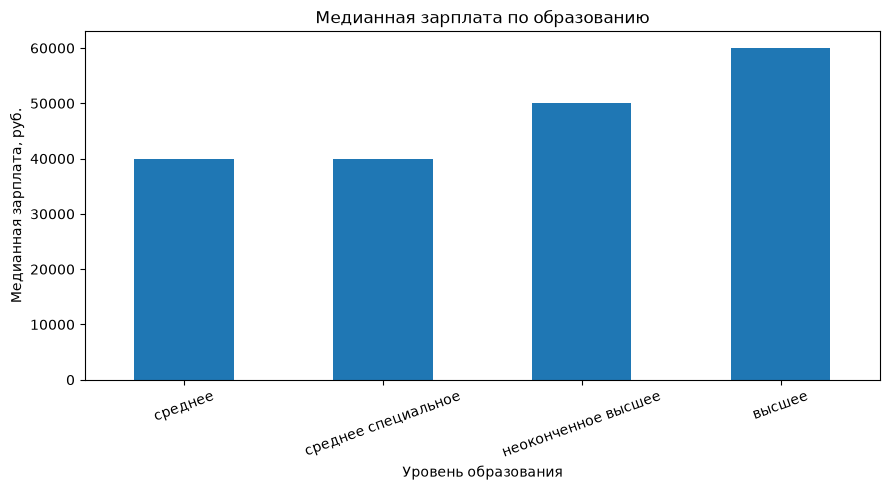

Образование
среднее                40000.0
среднее специальное    40000.0
неоконченное высшее    50000.0
высшее                 60000.0
Name: ЗП (руб), dtype: float64

In [124]:
MAX_SALARY_FOR_COMPARISON = 1_000_000
PLOT_SIZE = (9, 5)
LABEL_ROTATION = 20

salary_data = hh_data[hh_data["ЗП (руб)"] < MAX_SALARY_FOR_COMPARISON]
education_salary = salary_data.groupby("Образование")["ЗП (руб)"].median().sort_values()

education_salary.plot(kind="bar", figsize=PLOT_SIZE, title="Медианная зарплата по образованию")
plt.xlabel("Уровень образования")
plt.ylabel("Медианная зарплата, руб.")
plt.xticks(rotation=LABEL_ROTATION)
plt.tight_layout()
plt.show()

display(education_salary)


Наибольшая медианная желаемая зарплата у соискателей с **высшим образованием - 60 000 рублей**. При неоконченном высшем она составляет **50 000 рублей**, а наименьшая - **40 000 рублей** - у групп со средним и средним специальным образованием.

Уровень образования может быть полезным признаком для прогноза: медианы в группах различаются. При этом на зарплатные ожидания влияют и другие признаки, например опыт и город, поэтому по одной диаграмме нельзя заключить, что образование само вызвало эти различия.

5. Постройте диаграмму, которая показывает распределение желаемой заработной платы (**"ЗП (руб)"**) в зависимости от города (**"Город"**). Используйте для диаграммы данные о резюме, где желая заработная плата меньше 1 млн рублей.
*Сделайте выводы по полученной диаграмме: как соотносятся медианные уровни желаемой заработной платы и их размах в городах? Как вы считаете, важен ли признак города при прогнозировании заработной платы?*

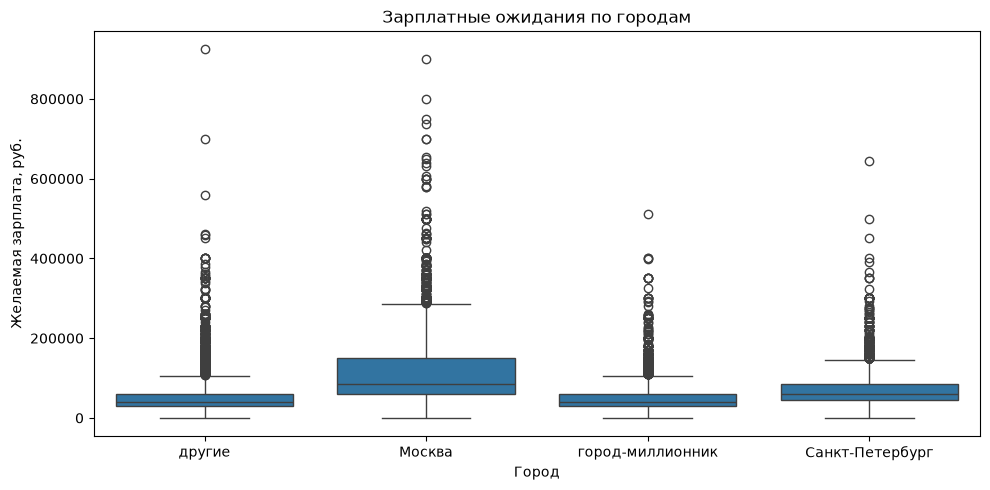

Город
Москва              85000.0
Санкт-Петербург     60000.0
город-миллионник    40000.0
другие              40000.0
Name: ЗП (руб), dtype: float64

'Максимальная зарплата по категориям городов:'

Город
Москва              900000.0
Санкт-Петербург     645171.0
город-миллионник    511681.6
другие              923983.0
Name: ЗП (руб), dtype: float64

'Первый и третий квартили зарплаты по городам:'

,0.25,0.75
Город,,
Москва,60000.00,150000.0
Санкт-Петербург,44772.14,85000.0
город-миллионник,30000.00,60000.0
другие,30000.00,60000.0


In [125]:
PLOT_SIZE = (10, 5)
FIRST_QUARTILE = 0.25
THIRD_QUARTILE = 0.75

plt.figure(figsize=PLOT_SIZE)
sns.boxplot(data=salary_data, x="Город", y="ЗП (руб)")
plt.title("Зарплатные ожидания по городам")
plt.xlabel("Город")
plt.ylabel("Желаемая зарплата, руб.")
plt.tight_layout()
plt.show()

display(salary_data.groupby("Город")["ЗП (руб)"].median())
display("Максимальная зарплата по категориям городов:")
display(salary_data.groupby("Город")["ЗП (руб)"].max())

display("Первый и третий квартили зарплаты по городам:")
display(salary_data.groupby("Город")["ЗП (руб)"].quantile([FIRST_QUARTILE, THIRD_QUARTILE]).unstack())


Медианная желаемая зарплата выше всего в **Москве - 85 000 рублей**, затем в **Санкт-Петербурге - 60 000 рублей**. В городах-миллионниках и категории "другие" медиана составляет **40 000 рублей**. Центральная половина значений в Москве шире: от 60 до 150 тысяч рублей. В Санкт-Петербурге - примерно от 45 до 85 тысяч, а в двух остальных категориях - от 30 до 60 тысяч.

Наибольшая желаемая зарплата ниже миллиона - **923 983 рубля** - находится в категории **"другие"**. **Да, признак города важен для прогнозирования желаемой заработной платы:** медианы и разброс по группам заметно различаются. Его следует учитывать вместе с профессией, опытом и другими признаками. По одной диаграмме нельзя оценить вклад города отдельно от них.

6. Постройте **многоуровневую столбчатую диаграмму**, которая показывает зависимость медианной заработной платы (**"ЗП (руб)"**) от признаков **"Готовность к переезду"** и **"Готовность к командировкам"**. Проанализируйте график, сравнив уровень заработной платы в категориях.

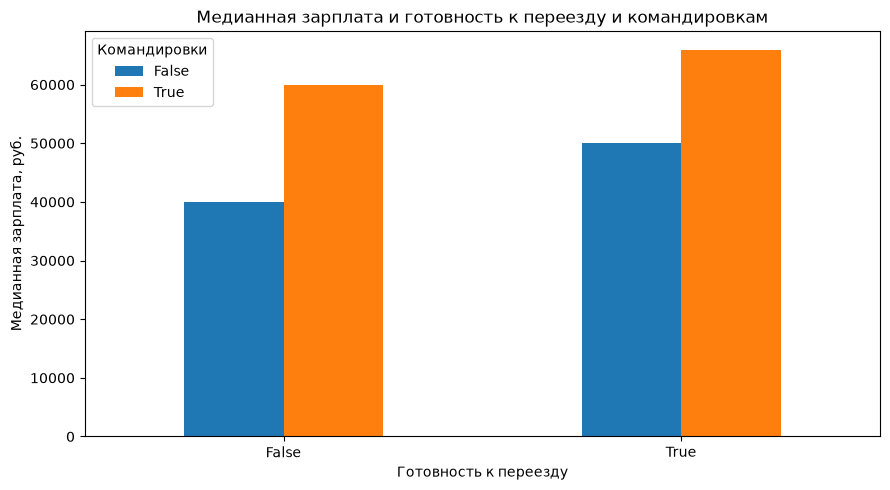

Готовность к командировкам,False,True
Готовность к переезду,,
False,40000.0,60000.000
True,50000.0,65849.455


In [126]:
PLOT_SIZE = (9, 5)

moving = hh_data.pivot_table(values="ЗП (руб)", index="Готовность к переезду", columns="Готовность к командировкам", aggfunc="median")

moving.plot(kind="bar", figsize=PLOT_SIZE, title="Медианная зарплата и готовность к переезду и командировкам")
plt.xlabel("Готовность к переезду")
plt.ylabel("Медианная зарплата, руб.")
plt.legend(title="Командировки")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(moving)


Наибольшая медианная желаемая зарплата - примерно **65 849 рублей** - у соискателей, готовых и к переезду, и к командировкам. У готовых только к командировкам медиана составляет **60 000 рублей**, только к переезду - **50 000 рублей**. Наименьшая медиана - **40 000 рублей** - у не готовых ни к переезду, ни к командировкам.

В обеих группах по готовности к переезду медианная зарплата выше у готовых к командировкам. Аналогично в обеих группах по командировкам она выше у готовых к переезду. Это связь в данных, а не доказательство того, что готовность сама по себе повышает зарплатные ожидания.

7. Постройте сводную таблицу, иллюстрирующую зависимость **медианной** желаемой заработной платы от возраста (**"Возраст"**) и образования (**"Образование"**). На полученной сводной таблице постройте **тепловую карту**. Проанализируйте тепловую карту, сравнив показатели внутри групп.

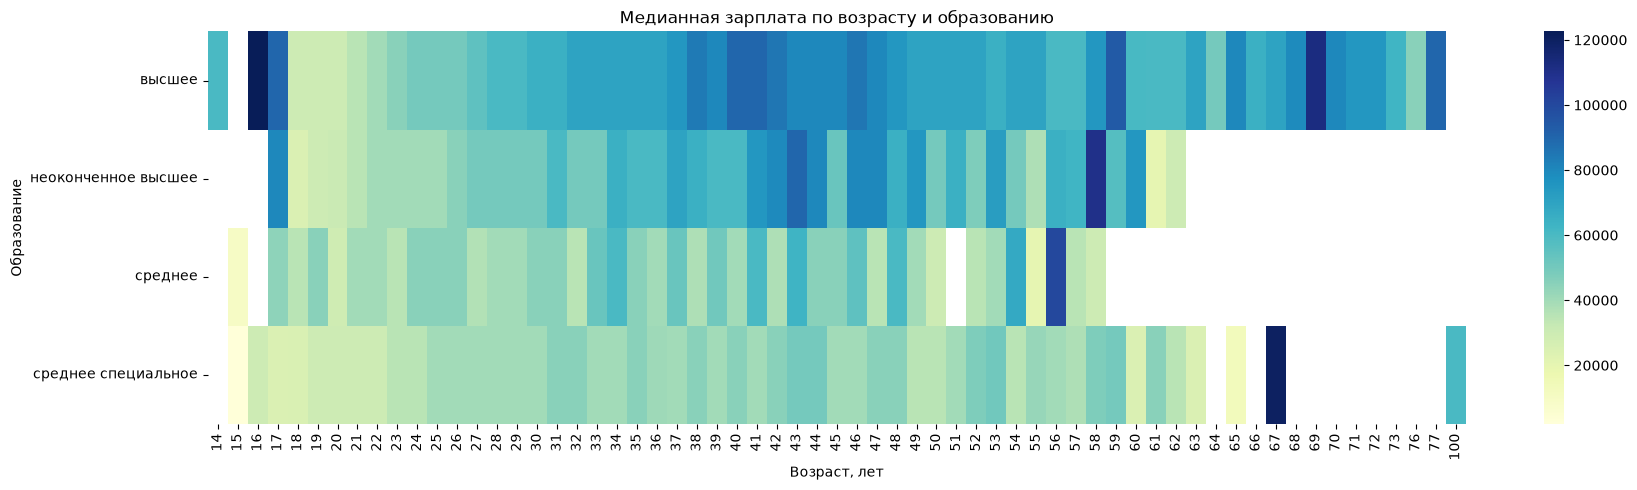

'Медианная зарплата по образованию для возрастов 20, 30 и 40 лет:'

Возраст,20,30,40
Образование,,,
высшее,30000.0,65000.0,90000.0
неоконченное высшее,31000.0,50000.0,60000.0
среднее,29000.0,45000.0,40000.0
среднее специальное,30000.0,40000.0,45000.0


'Количество резюме в группах:'

Возраст,20,30,40
Образование,,,
высшее,79.0,2234.0,753.0
неоконченное высшее,142.0,273.0,54.0
среднее,26.0,28.0,11.0
среднее специальное,158.0,299.0,59.0


In [127]:
HEATMAP_COLOR_SCHEME = "YlGnBu"
PLOT_SIZE = (18, 5)
COMPARISON_AGES = [20, 30, 40]

age_education = hh_data.pivot_table(values="ЗП (руб)", index="Образование", columns="Возраст", aggfunc="median")

plt.figure(figsize=PLOT_SIZE)
sns.heatmap(age_education, cmap=HEATMAP_COLOR_SCHEME)
plt.title("Медианная зарплата по возрасту и образованию")
plt.xlabel("Возраст, лет")
plt.ylabel("Образование")
plt.tight_layout()
plt.show()

display("Медианная зарплата по образованию для возрастов 20, 30 и 40 лет:")
display(age_education[COMPARISON_AGES])
display("Количество резюме в группах:")
display(hh_data.pivot_table(values="ЗП (руб)", index="Образование", columns="Возраст", aggfunc="count")[COMPARISON_AGES])


Наиболее выраженный рост медианной желаемой зарплаты по возрастным группам наблюдается у соискателей с **высшим образованием**. Например, медиана этой группы составляет 30 000 рублей в 20 лет, 65 000 рублей в 30 лет и 90 000 рублей в 40 лет. Для сравнения, у соискателей со средним специальным образованием медиана в этих возрастах - 30 000, 40 000 и 45 000 рублей соответственно.

В отдельных возрастах и категориях резюме мало, поэтому их медианы могут сильно колебаться. Карта сравнивает ожидания разных людей, а не отслеживает зарплату одних и тех же соискателей. Вывод о "карьерном росте" здесь условный.

8. Постройте **диаграмму рассеяния**, показывающую зависимость опыта работы (**"Опыт работы (месяц)"**) от возраста (**"Возраст"**). Опыт работы переведите из месяцев в года, чтобы признаки были в едином масштабе. Постройте на графике дополнительно прямую, проходящую через точки (0, 0) и (100, 100). Данная прямая соответствует значениям, когда опыт работы равен возрасту человека. Точки, лежащие на этой прямой и выше нее - аномалии в наших данных (опыт работы больше либо равен возрасту соискателя)

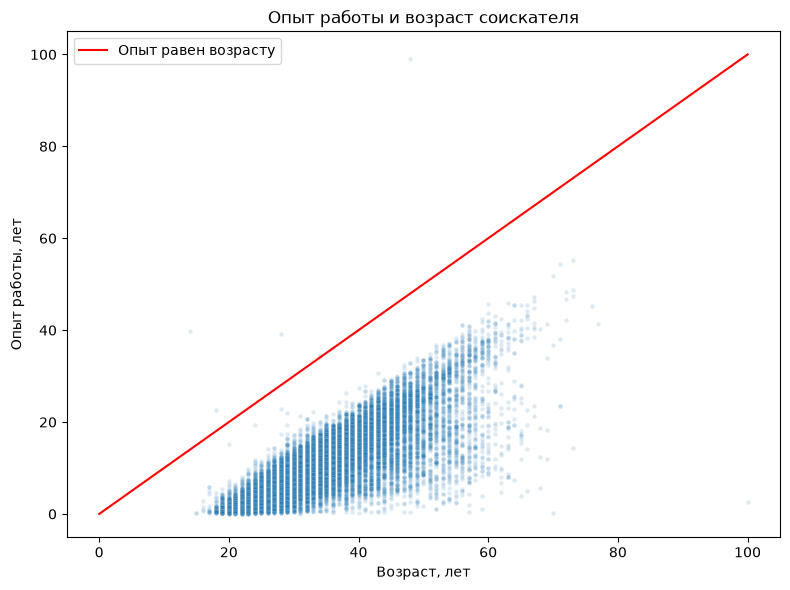

'Опыт строго больше возраста: 7 резюме'

,Возраст,Опыт работы (месяц)
4535,18,271.0
19351,28,470.0
19872,34,416.0
26477,34,411.0
29098,14,477.0
40015,48,1188.0
43451,36,434.0


'Точек на прямой: 0'

In [128]:
PLOT_SIZE = (8, 6)
REFERENCE_AGE_LIMIT = 100
POINT_ALPHA = 0.15
POINT_SIZE = 10

plt.figure(figsize=PLOT_SIZE)
sns.scatterplot(data=hh_data, x="Возраст", y=hh_data["Опыт работы (месяц)"] / MONTHS_PER_YEAR, alpha=POINT_ALPHA, s=POINT_SIZE)
plt.plot([0, REFERENCE_AGE_LIMIT], [0, REFERENCE_AGE_LIMIT], color="red", label="Опыт равен возрасту")
plt.title("Опыт работы и возраст соискателя")
plt.xlabel("Возраст, лет")
plt.ylabel("Опыт работы, лет")
plt.legend()
plt.tight_layout()
plt.show()

above_line = hh_data["Опыт работы (месяц)"] / MONTHS_PER_YEAR > hh_data["Возраст"]

display(f"Опыт строго больше возраста: {above_line.sum()} резюме")
display(hh_data.loc[above_line, ["Возраст", "Опыт работы (месяц)"]])

on_line = hh_data["Опыт работы (месяц)"] / MONTHS_PER_YEAR == hh_data["Возраст"]

display(f"Точек на прямой: {on_line.sum()}")


Строго выше прямой лежат **7 точек**: у этих соискателей указанный опыт работы больше возраста. Точек, лежащих точно на прямой, в данных нет. Эти записи требуют проверки.

**Дополнительные баллы**

Для получения 2 дополнительных баллов по разведывательному анализу постройте еще два любых содержательных графика или диаграммы, которые помогут проиллюстрировать влияние признаков/взаимосвязь между признаками/распределения признаков. Приведите выводы по ним. Желательно, чтобы в анализе участвовали признаки, которые мы создавали ранее в разделе "Преобразование данных".


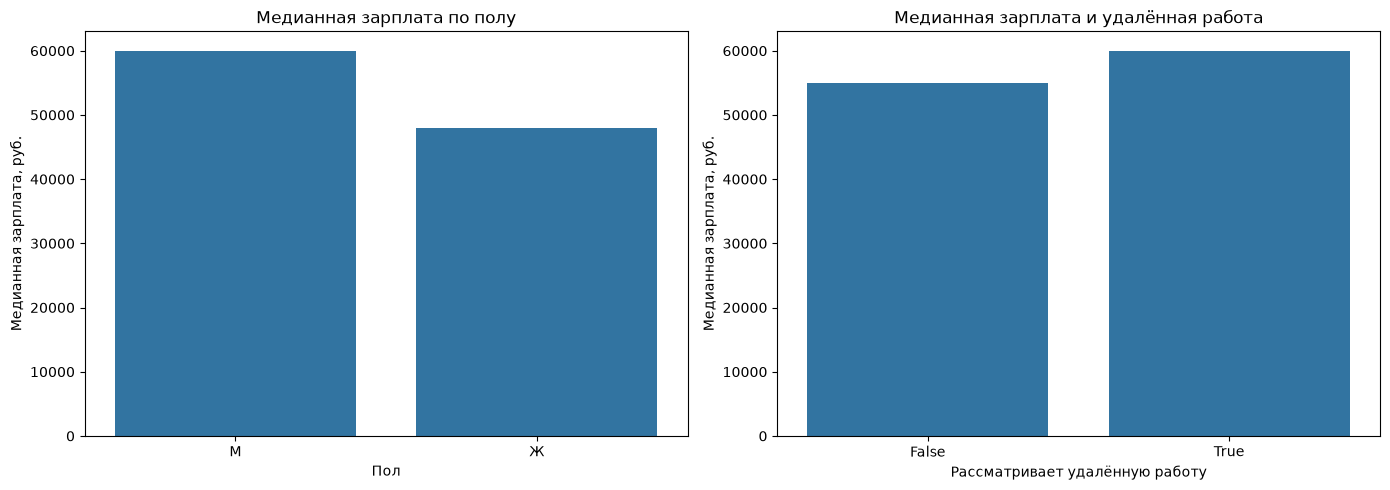

Пол
Ж    48000.0
М    60000.0
Name: ЗП (руб), dtype: float64

удаленная работа
False    55000.0
True     60000.0
Name: ЗП (руб), dtype: float64

In [129]:
PLOT_SIZE = (14, 5)

fig, axes = plt.subplots(1, 2, figsize=PLOT_SIZE)

sns.barplot(data=salary_data, x="Пол", y="ЗП (руб)", estimator=np.median, errorbar=None, ax=axes[0])
axes[0].set(title="Медианная зарплата по полу", xlabel="Пол", ylabel="Медианная зарплата, руб.")
sns.barplot(data=salary_data, x="удаленная работа", y="ЗП (руб)", estimator=np.median, errorbar=None, ax=axes[1])
axes[1].set(title="Медианная зарплата и удалённая работа", xlabel="Рассматривает удалённую работу", ylabel="Медианная зарплата, руб.")
plt.tight_layout()
plt.show()

display(salary_data.groupby("Пол")["ЗП (руб)"].median())
display(salary_data.groupby("удаленная работа")["ЗП (руб)"].median())


**Пол и зарплатные ожидания.** Среди резюме с желаемой зарплатой менее 1 млн рублей медиана составляет **60 000 рублей** у мужчин и **48 000 рублей** у женщин. Это сравнение не учитывает различия в профессии, опыте, городе и других признаках.

**Удалённая работа и зарплатные ожидания.** У рассматривающих удалённую работу медиана составляет **60 000 рублей**, у остальных - **55 000 рублей**. Признак может быть полезен для анализа, но разница медиан сама по себе не доказывает влияние удалённой работы на зарплату.

# Очистка данных

1. Начнем с дубликатов в наших данных. Найдите **полные дубликаты** в таблице с резюме и удалите их. 

In [130]:
duplicates = hh_data.duplicated()

duplicate_count = duplicates.sum()
display(f"Полных дубликатов: {duplicate_count}")

hh_data = hh_data.drop_duplicates()


'Полных дубликатов: 161'

Найдена **161 полная копия** строки в преобразованной таблице. Дубликаты удалены. По одному экземпляру каждой строки сохранено.

2. Займемся пропусками. Выведите информацию **о числе пропусков** в столбцах. 

In [131]:
display(hh_data.isna().sum().sort_values(ascending=False))


Опыт работы (месяц)                168
Последняя/нынешняя должность         2
Последнее/нынешнее место работы      1
Ищет работу на должность:            0
частичная занятость                  0
вахтовый метод                       0
удаленная работа                     0
гибкий график                        0
сменный график                       0
полный день                          0
стажировка                           0
волонтерство                         0
проектная работа                     0
Готовность к командировкам           0
полная занятость                     0
Готовность к переезду                0
Город                                0
Возраст                              0
Пол                                  0
Образование                          0
Авто                                 0
Обновление резюме                    0
ЗП (руб)                             0
dtype: int64

В столбце "Опыт работы (месяц)" - **168 пропусков**.

3. Итак, у нас есть пропуски в 3ех столбцах: **"Опыт работы (месяц)"**, **"Последнее/нынешнее место работы"**, **"Последняя/нынешняя должность"**. Поступим следующим образом: удалите строки, где есть пропуск в столбцах с местом работы и должностью. Пропуски в столбце с опытом работы заполните **медианным** значением.

In [132]:
hh_data = hh_data.dropna(subset=["Последнее/нынешнее место работы", "Последняя/нынешняя должность"])

hh_data["Опыт работы (месяц)"] = hh_data["Опыт работы (месяц)"].fillna(hh_data["Опыт работы (месяц)"].median())

display(hh_data.isna().sum())
mean_experience = round(hh_data["Опыт работы (месяц)"].mean())
display(f"Средний опыт после заполнения, месяцев: {mean_experience}")


Ищет работу на должность:          0
Последнее/нынешнее место работы    0
Последняя/нынешняя должность       0
Обновление резюме                  0
Авто                               0
Образование                        0
Пол                                0
Возраст                            0
Опыт работы (месяц)                0
Город                              0
Готовность к переезду              0
Готовность к командировкам         0
полная занятость                   0
частичная занятость                0
проектная работа                   0
волонтерство                       0
стажировка                         0
полный день                        0
сменный график                     0
гибкий график                      0
удаленная работа                   0
вахтовый метод                     0
ЗП (руб)                           0
dtype: int64

'Средний опыт после заполнения, месяцев: 114'

После удаления строк с пропусками в месте работы и должности и заполнения опыта медианой средний опыт составляет **114 месяцев**.

4. Мы добрались до ликвидации выбросов. Сначала очистим данные вручную. Удалите резюме, в которых указана заработная плата либо выше 1 млн. рублей, либо ниже 1 тыс. рублей.

In [133]:
MIN_VALID_SALARY = 1_000
MAX_VALID_SALARY = 1_000_000

salary_outliers = (hh_data["ЗП (руб)"] < MIN_VALID_SALARY) | (hh_data["ЗП (руб)"] > MAX_VALID_SALARY)

low_salary_count = (hh_data["ЗП (руб)"] < MIN_VALID_SALARY).sum()
display(f"Ниже 1000 рублей: {low_salary_count}")
high_salary_count = (hh_data["ЗП (руб)"] > MAX_VALID_SALARY).sum()
display(f"Выше 1 млн рублей: {high_salary_count}")
salary_outlier_count = salary_outliers.sum()
display(f"Выбросов зарплаты: {salary_outlier_count}")

salary_outliers_indexes = hh_data[salary_outliers].index
hh_data = hh_data.drop(index=salary_outliers_indexes)

missing_salary_count = hh_data["ЗП (руб)"].isna().sum()
display(f"Зарплаты в иностранных валютах остались пропусками: {missing_salary_count}")


'Ниже 1000 рублей: 84'

'Выше 1 млн рублей: 5'

'Выбросов зарплаты: 89'

'Зарплаты в иностранных валютах остались пропусками: 0'

Найдено и удалено **89 выбросов**: 84 зарплаты ниже 1 000 рублей и 5 зарплат выше 1 000 000 рублей. Граничные значения сохраняются.

5. В процессе разведывательного анализа мы обнаружили резюме, в которых **опыт работы в годах превышал возраст соискателя**. Найдите такие резюме и удалите их из данных


In [134]:
experience_outliers = hh_data["Опыт работы (месяц)"] / MONTHS_PER_YEAR > hh_data["Возраст"]

experience_outlier_count = experience_outliers.sum()
display(f"Опыт больше возраста: {experience_outlier_count}")

experience_outliers_indexes = hh_data[experience_outliers].index
hh_data = hh_data.drop(index=experience_outliers_indexes)


'Опыт больше возраста: 7'

Найдено и удалено **7 резюме**, в которых опыт работы в годах строго превышает возраст соискателя.

6. В результате анализа мы обнаружили потенциальные выбросы в признаке **"Возраст"**. Это оказались резюме людей чересчур преклонного возраста для поиска работы. Попробуйте построить распределение признака в **логарифмическом масштабе**. Добавьте к графику линии, отображающие **среднее и границы интервала метода трех сигм**. Напомним, сделать это можно с помощью метода axvline. Например, для построение линии среднего будет иметь вид:

`histplot.axvline(log_age.mean(), color='k', lw=2)`

В какую сторону асимметрично логарифмическое распределение? Напишите об этом в комментарии к графику.
Найдите выбросы с помощью метода z-отклонения и удалите их из данных, используйте логарифмический масштаб. Давайте сделаем послабление на **1 сигму** (возьмите 4 сигмы) в **правую сторону**.

Выведите таблицу с полученными выбросами и оцените, с каким возрастом соискатели попадают под категорию выбросов?

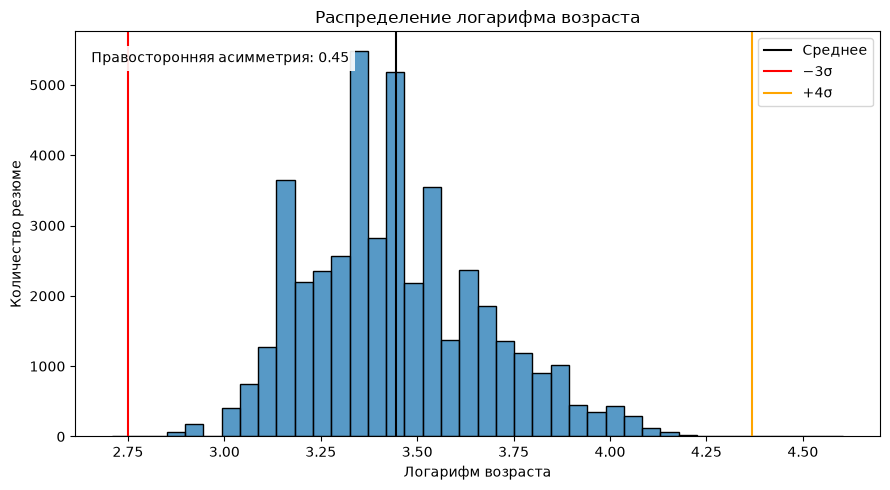

'Выбросов: 3'

,Ищет работу на должность:,Последнее/нынешнее место работы,Последняя/нынешняя должность,Обновление резюме,Авто,Образование,Пол,Возраст,Опыт работы (месяц),Город,...,частичная занятость,проектная работа,волонтерство,стажировка,полный день,сменный график,гибкий график,удаленная работа,вахтовый метод,ЗП (руб)
31137,Менеджер по работе с клиентами,"ООО ""ФёрстКэшКомпани""",Менеджер по работе с клиентами,2019-04-06,Не указано,среднее,М,15,2.0,Санкт-Петербург,...,True,False,False,False,False,True,True,True,False,10000.0
32950,Тестировщик игр,OOO ЖМЫХ,Тестировщик ПО,2019-04-09,Не указано,среднее специальное,М,15,3.0,другие,...,False,False,False,False,True,False,False,False,False,2000.0
33654,Frontend-разработчик,Freelance,Frontend-разработчик,2019-04-19,Не указано,среднее специальное,М,100,30.0,Санкт-Петербург,...,True,True,False,True,True,False,True,True,False,60000.0


'Итоговый размер: (44482, 23)'

'Асимметрия логарифма возраста: 0.45234222760537585'

In [135]:
PLOT_SIZE = (9, 5)
AGE_LOG_BINS = 40
ANNOTATION_POSITION = (0.02, 0.95)
LEFT_SIGMAS = 3
RIGHT_SIGMAS = 4

log_age = np.log(hh_data["Возраст"])
mean = log_age.mean()
std = log_age.std()
log_age_skewness = log_age.skew()
lower = mean - LEFT_SIGMAS * std
upper = mean + RIGHT_SIGMAS * std

plt.figure(figsize=PLOT_SIZE)
sns.histplot(log_age, bins=AGE_LOG_BINS)
plt.axvline(mean, color="black", label="Среднее")
plt.axvline(lower, color="red", label="−3σ")
plt.axvline(upper, color="orange", label="+4σ")
plt.title("Распределение логарифма возраста")
plt.annotate(
    f"Правосторонняя асимметрия: {log_age_skewness:.2f}",
    xy=ANNOTATION_POSITION,
    xycoords="axes fraction",
    verticalalignment="top",
    bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9}
)
plt.xlabel("Логарифм возраста")
plt.ylabel("Количество резюме")
plt.legend()
plt.tight_layout()
plt.show()

age_outliers = (log_age < lower) | (log_age > upper)

age_outlier_count = age_outliers.sum()
display(f"Выбросов: {age_outlier_count}")
display(hh_data.loc[age_outliers].sort_values("Возраст"))

age_outliers_indexes = hh_data[age_outliers].index
hh_data = hh_data.drop(index=age_outliers_indexes)

final_shape = hh_data.shape
display(f"Итоговый размер: {final_shape}")

display(f"Асимметрия логарифма возраста: {log_age_skewness}")


Коэффициент асимметрии логарифма возраста положительный (примерно 0,45), поэтому распределение имеет **правостороннюю асимметрию**. По границам -3σ и +4σ найдено **3 выброса**: два резюме с возрастом 15 лет и одно - с возрастом 100 лет. Это статистические выбросы. Сам возраст не доказывает ошибку. Эти строки удалены из данных.